In [25]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
df=pd.read_csv('weight-height.csv')

In [27]:
df

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


In [28]:
df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


<Axes: xlabel='Weight', ylabel='Count'>

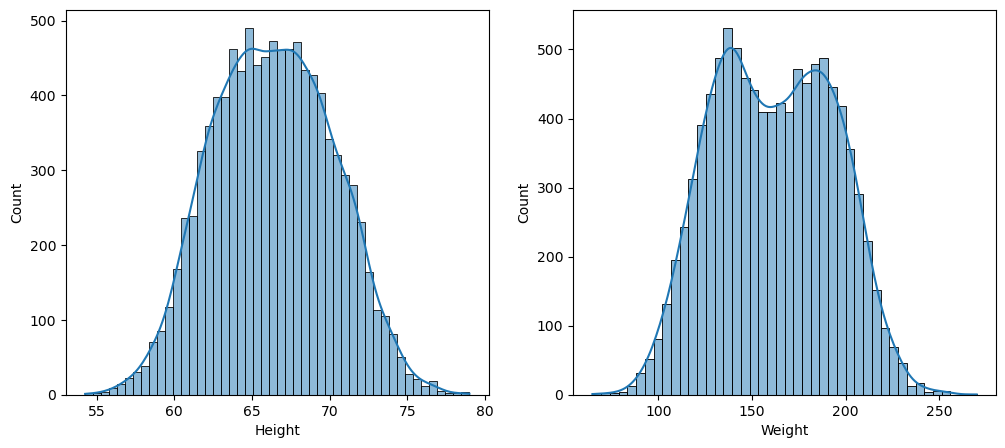

In [29]:
plt.figure(figsize=(12,5))
plt.subplot(121)
sns.histplot(df['Height'],kde=True)

plt.subplot(122)
sns.histplot(df['Weight'],kde=True)

<Axes: xlabel='Weight'>

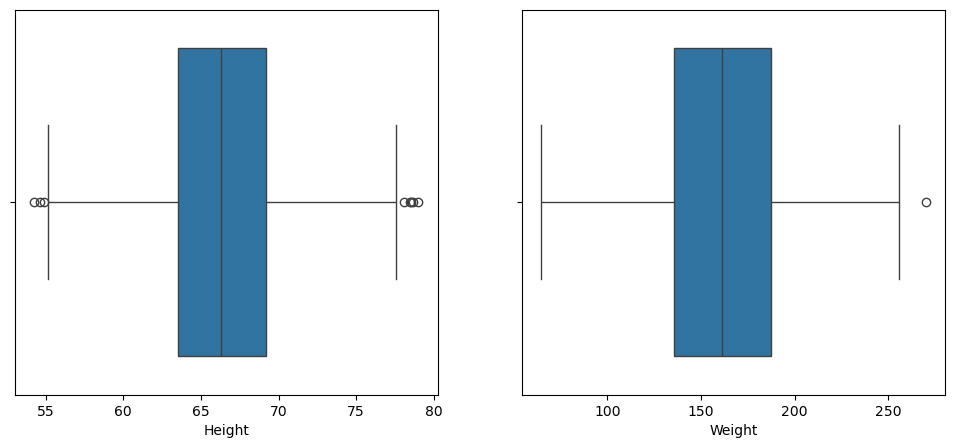

In [30]:
plt.figure(figsize=(12,5))
plt.subplot(121)
sns.boxplot(x=df['Height'])

plt.subplot(122)
sns.boxplot(x=df['Weight'])

In [31]:
upper_limit=df['Height'].quantile(0.99)
lower_limit=df['Height'].quantile(0.01)

In [32]:
upper_limit

74.7857900583366

In [33]:
lower_limit

58.13441158671655

now we have upper and lower limit now we can do two things either we can remove/trim them or we can cap them we will do both one by one

# trim

In [34]:
df[(df['Height']<=lower_limit) | (df['Height']>=upper_limit)]

,Gender,Height,Weight
23,Male,75.205974,228.761781
190,Male,76.709835,235.035419
197,Male,75.944460,231.924749
202,Male,75.140821,224.124271
215,Male,74.795375,232.635403
...,...,...,...
9761,Female,56.975279,90.341784
9825,Female,55.979198,85.417534
9895,Female,57.740192,93.652957
9904,Female,57.028857,101.202551


In [35]:
new_df = df[(df['Height']>lower_limit) & (df['Height']<upper_limit)]

In [36]:
new_df

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


<Axes: xlabel='Height'>

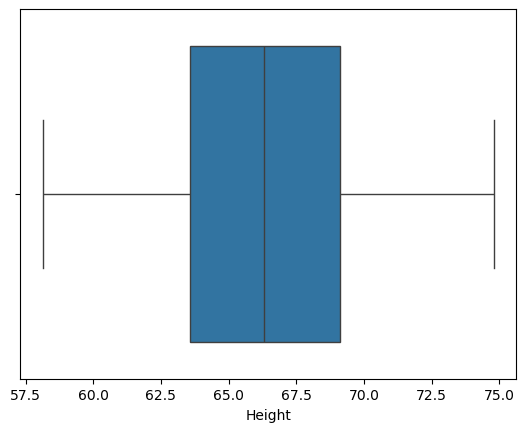

In [37]:
sns.boxplot(x=new_df['Height'])

In [38]:
new_df.describe()

,Height,Weight
count,9800.000000,9800.000000
mean,66.364366,161.399489
std,3.645075,30.933549
min,58.134496,77.523774
25%,63.577162,136.322717
50%,66.318070,161.212928
75%,69.119896,186.753317
max,74.785714,249.946283


In [39]:
df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


<Axes: xlabel='Height', ylabel='Count'>

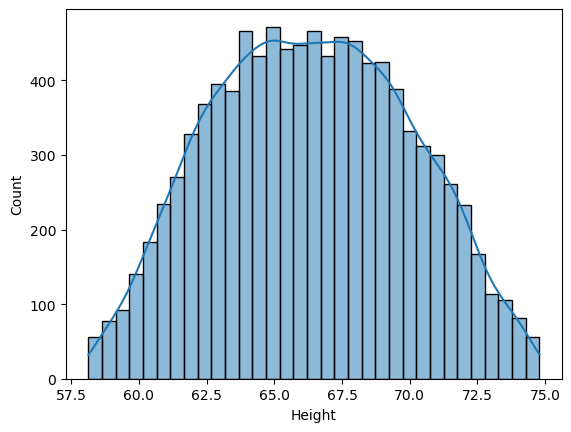

In [40]:
sns.histplot(new_df['Height'],kde=True)

# Capping (winsorization)

In [43]:
df_cap=df.copy()
df_cap['Height']=np.where(df['Height']>upper_limit,upper_limit,np.where(df['Height']<lower_limit,lower_limit,df['Height']))

In [44]:
df_cap

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


<Axes: xlabel='Height'>

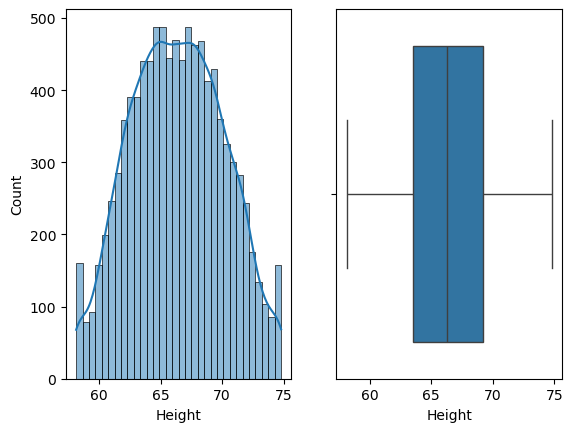

In [45]:
plt.figure()

plt.subplot(121)
sns.histplot(df_cap['Height'],kde=True)

plt.subplot(122)
sns.boxplot(x=df_cap['Height'])

In [46]:
df_cap.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.366281,161.440357
std,3.795717,32.108439
min,58.134412,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,74.785790,269.989699
